# Bellabeat case study: analysis

Data is read directly from the `fitbit_mart` star schema in BigQuery
(see `docs/data_model.md`). Each section tests one hypothesis and ends
with a one-sentence finding.

## 0. Setup and data load

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.cloud import bigquery

PROJECT_ID = "bellabeat-case-study-513614"
client = bigquery.Client(project=PROJECT_ID)

def run_query(sql):
    return client.query(sql).to_dataframe(create_bqstorage_client=False)

In [3]:
run_query("""
SELECT activity_segment, COUNT(*) AS users
FROM fitbit_mart.dim_user
GROUP BY activity_segment, activity_segment_order
ORDER BY activity_segment_order
""")

,activity_segment,users
0,Sedentary,9
1,Low active,8
2,Somewhat active,9
3,Active,9


In [4]:
tables = [
    "dim_user", "dim_date", "dim_hour",
    "fact_daily_activity", "fact_hourly_activity",
    "fact_sleep", "fact_heart_rate_daily", "fact_weight_log",
]

data = {name: run_query(f"SELECT * FROM fitbit_mart.{name}") for name in tables}

for name, df in data.items():
    print(f"{name:<24}{df.shape[0]:>8} rows {df.shape[1]:>4} columns")

dim_user                      35 rows   16 columns
dim_date                      62 rows   10 columns
dim_hour                      24 rows    4 columns
fact_daily_activity         1966 rows   17 columns
fact_hourly_activity       46008 rows   10 columns
fact_sleep                   832 rows   11 columns
fact_heart_rate_daily        469 rows    7 columns
fact_weight_log               98 rows    7 columns


## 1. H1: Does engagement decline over time?

In [5]:
daily = data["fact_daily_activity"].merge(
    data["dim_date"][["date", "study_day", "study_week", "day_of_week", "is_weekend"]],
    left_on="activity_date",
    right_on="date",
    how="left",
)
n_users = len(data["dim_user"])
valid = daily[daily["is_valid_day"]]

print(daily.shape, n_users, valid.shape)

(1966, 22) 35 (1664, 22)


In [6]:
weekly = daily.groupby("study_week").agg(
    users_in_data=("user_id", "nunique"),
    days_in_week=("activity_date", "nunique"),
)
weekly["users_with_valid_day"] = valid.groupby("study_week")["user_id"].nunique()
weekly["valid_days"] = valid.groupby("study_week").size()
weekly["avg_steps_valid_days"] = valid.groupby("study_week")["total_steps"].mean().round()

weekly["pct_users_in_data"] = (100 * weekly["users_in_data"] / n_users).round(1)
weekly["pct_users_valid"] = (100 * weekly["users_with_valid_day"] / n_users).round(1)
weekly["valid_day_rate"] = (
    weekly["valid_days"] / (n_users * weekly["days_in_week"])
).round(3)

weekly

,users_in_data,days_in_week,users_with_valid_day,valid_days,avg_steps_valid_days,pct_users_in_data,pct_users_valid,valid_day_rate
study_week,,,,,,,,
1,33,7,29,187,8980.0,94.3,82.9,0.763
2,33,7,28,173,7821.0,94.3,80.0,0.706
3,35,7,30,192,8048.0,100.0,85.7,0.784
4,35,7,33,204,8477.0,100.0,94.3,0.833
5,34,7,33,198,7999.0,97.1,94.3,0.808
6,32,7,32,208,8444.0,91.4,91.4,0.849
7,32,7,31,202,8603.0,91.4,88.6,0.824
8,31,7,30,191,8282.0,88.6,85.7,0.780
9,29,6,25,109,8882.0,82.9,71.4,0.519


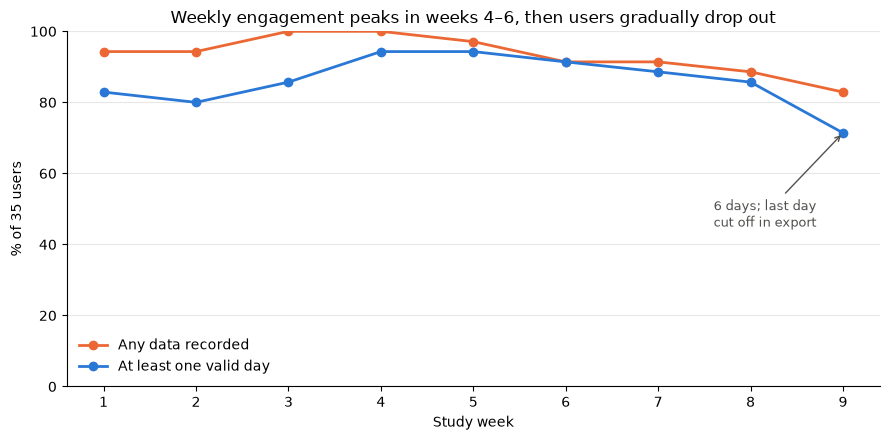

In [7]:
import os
os.makedirs("../docs/figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(weekly.index, weekly["pct_users_in_data"], marker="o", linewidth=2,
        color="#EB6834", label="Any data recorded")
ax.plot(weekly.index, weekly["pct_users_valid"], marker="o", linewidth=2,
        color="#2A78D6", label="At least one valid day")

ax.set_ylim(0, 100)
ax.set_xticks(weekly.index)
ax.set_xlabel("Study week")
ax.set_ylabel(f"% of {n_users} users")
ax.set_title("Weekly engagement peaks in weeks 4–6, then users gradually drop out")
ax.annotate("6 days; last day\ncut off in export", xy=(9, weekly.loc[9, "pct_users_valid"]),
            xytext=(7.6, 45), arrowprops=dict(arrowstyle="->", color="#52514E"),
            color="#52514E", fontsize=9)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left")

fig.tight_layout()
fig.savefig("../docs/figures/h1_weekly_engagement.png", dpi=150)
plt.show()

„Engagement does not fade gradually among users who stay: valid-day share and activity are unchanged between the two months. The risks are at both ends: a weaker first two weeks (onboarding) and about one in nine users dropping out entirely within a month.“

In [9]:
from scipy import stats

days_per_period = data["dim_date"].groupby("period").size()

valid_share = (
    daily.groupby(["user_id", "period"])["is_valid_day"].sum()
    .unstack(fill_value=0)
    .div(days_per_period, axis=1)
)

w_share = stats.wilcoxon(valid_share[1], valid_share[2])
print("Valid-day share per user")
print(f"  mean   P1 = {valid_share[1].mean():.3f}, P2 = {valid_share[2].mean():.3f}")
print(f"  median P1 = {valid_share[1].median():.3f}, P2 = {valid_share[2].median():.3f}")
print(f"  lower in P2: {(valid_share[2] < valid_share[1]).sum()} users, "
      f"higher: {(valid_share[2] > valid_share[1]).sum()}, "
      f"equal: {(valid_share[2] == valid_share[1]).sum()}")
print(f"  Wilcoxon signed-rank: W = {w_share.statistic:.1f}, p = {w_share.pvalue:.3f}")

steps = valid.groupby(["user_id", "period"])["total_steps"].mean().unstack().dropna()
w_steps = stats.wilcoxon(steps[1], steps[2])
print(f"\nAverage steps on valid days ({len(steps)} users with valid days in both periods)")
print(f"  mean P1 = {steps[1].mean():.0f}, P2 = {steps[2].mean():.0f}")
print(f"  Wilcoxon signed-rank: W = {w_steps.statistic:.1f}, p = {w_steps.pvalue:.3f}")

Valid-day share per user
  mean   P1 = 0.764, P2 = 0.770
  median P1 = 0.935, P2 = 0.935
  lower in P2: 21 users, higher: 12, equal: 2
  Wilcoxon signed-rank: W = 258.5, p = 0.694

Average steps on valid days (32 users with valid days in both periods)
  mean P1 = 7834, P2 = 7967
  Wilcoxon signed-rank: W = 234.0, p = 0.586


## 2. H2: Is the device worn overnight?

In [10]:
users = data["dim_user"].copy()
users["sleep_tracking_rate"] = users["nights_tracked"] / users["days_in_data"]

users["sleep_group"] = np.select(
    [users["nights_tracked"] == 0, users["sleep_tracking_rate"] < 0.5],
    ["Never", "Occasional"],
    default="Regular",
)

group_order = ["Never", "Occasional", "Regular"]
sleep_summary = (
    users.groupby("sleep_group")
    .agg(
        users=("user_id", "size"),
        median_nights=("nights_tracked", "median"),
        median_tracking_rate=("sleep_tracking_rate", "median"),
        median_valid_day_share=("valid_day_share", "median"),
        median_avg_steps=("avg_daily_steps", "median"),
    )
    .reindex(group_order)
    .round(3)
)
sleep_summary

,users,median_nights,median_tracking_rate,median_valid_day_share,median_avg_steps
sleep_group,,,,,
Never,10,0.0,0.0,0.712,6314.0
Occasional,11,8.0,0.129,0.774,5416.0
Regular,14,51.5,0.856,0.960,8575.5


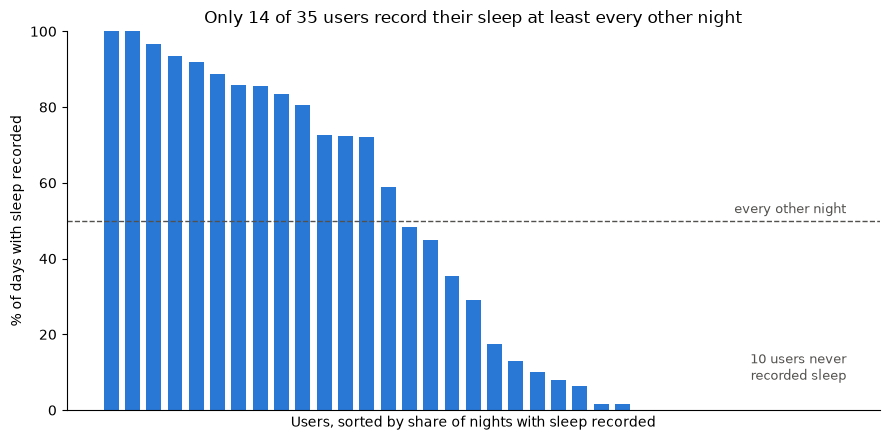

In [11]:
plot_df = users.sort_values("sleep_tracking_rate", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(plot_df.index + 1, 100 * plot_df["sleep_tracking_rate"], color="#2A78D6", width=0.7)
ax.axhline(50, color="#52514E", linestyle="--", linewidth=1)
ax.text(35.5, 52, "every other night", ha="right", color="#52514E", fontsize=9)

n_never = (users["nights_tracked"] == 0).sum()
ax.text(35.5, 8, f"{n_never} users never\nrecorded sleep", ha="right", color="#52514E", fontsize=9)

ax.set_ylim(0, 100)
ax.set_xlabel("Users, sorted by share of nights with sleep recorded")
ax.set_ylabel("% of days with sleep recorded")
ax.set_title(f"Only {(users['sleep_group'] == 'Regular').sum()} of {n_users} users "
             "record their sleep at least every other night")
ax.set_xticks([])
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()
fig.savefig("../docs/figures/h2_sleep_tracking.png", dpi=150)
plt.show()

In [12]:
trackers = users[users["nights_tracked"] > 0]
non_trackers = users[users["nights_tracked"] == 0]

for col, label in [("avg_daily_steps", "Average daily steps"),
                   ("valid_day_share", "Valid-day share")]:
    test = stats.mannwhitneyu(trackers[col], non_trackers[col], alternative="two-sided")
    print(f"{label}: median trackers = {trackers[col].median():.3f}, "
          f"non-trackers = {non_trackers[col].median():.3f}, "
          f"U = {test.statistic:.1f}, p = {test.pvalue:.3f}")

Average daily steps: median trackers = 8136.000, non-trackers = 6314.000, U = 171.0, p = 0.097
Valid-day share: median trackers = 0.935, non-trackers = 0.712, U = 168.5, p = 0.114


In [13]:
wear = daily.merge(
    data["fact_heart_rate_daily"][["user_id", "activity_date", "minutes_with_hr"]],
    on=["user_id", "activity_date"],
    how="inner",
)
wear["wear_hours"] = wear["minutes_with_hr"] / 60

valid_wear = wear[wear["is_valid_day"]]["wear_hours"]
invalid_wear = wear[~wear["is_valid_day"]]

print(f"Days with heart-rate data: {len(wear)} "
      f"({wear['is_valid_day'].sum()} valid, {(~wear['is_valid_day']).sum()} not valid)")
print(f"Valid days: median wear = {valid_wear.median():.1f} h, "
      f"worn >= 10 h: {(valid_wear >= 10).mean():.1%}, "
      f">= 20 h: {(valid_wear >= 20).mean():.1%}, "
      f"< 4 h: {(valid_wear < 4).mean():.1%}")
print(f"Not valid days: median wear = {invalid_wear['wear_hours'].median():.1f} h; "
      f"zero-step days: median wear = "
      f"{invalid_wear.loc[invalid_wear['is_zero_step_day'], 'wear_hours'].median():.1f} h")

Days with heart-rate data: 469 (452 valid, 17 not valid)
Valid days: median wear = 16.6 h, worn >= 10 h: 88.7%, >= 20 h: 43.6%, < 4 h: 4.2%
Not valid days: median wear = 8.0 h; zero-step days: median wear = 0.2 h


In [14]:
bins = [-np.inf, 5000, 7500, 10000, np.inf]
labels = ["Sedentary", "Low active", "Somewhat active", "Active"]

strict = daily[daily["is_valid_day"] & (daily["total_steps"] >= 1000)]
strict_steps = strict.groupby("user_id")["total_steps"].mean()

seg = users.set_index("user_id")[["activity_segment"]].copy()
seg["segment_strict"] = pd.cut(strict_steps, bins=bins, labels=labels, right=False)

print(f"Valid days: {len(valid)} -> {len(strict)} with the stricter rule "
      f"({len(valid) - len(strict)} removed)")
print(f"Mean steps on valid days: {valid['total_steps'].mean():.0f} -> "
      f"{strict['total_steps'].mean():.0f}")
print(f"Users changing segment: "
      f"{(seg['activity_segment'] != seg['segment_strict'].astype(str)).sum()}")
pd.crosstab(seg["activity_segment"], seg["segment_strict"]).reindex(index=labels, columns=labels)

Valid days: 1664 -> 1613 with the stricter rule (51 removed)
Mean steps on valid days: 8374 -> 8627
Users changing segment: 4


segment_strict,Sedentary,Low active,Somewhat active,Active
activity_segment,,,,
Sedentary,5,4,0,0
Low active,0,8,0,0
Somewhat active,0,0,9,0
Active,0,0,0,9


**Finding (H2):** Overnight wear is the weakest part of engagement: 10 of 35 users
never recorded sleep and 11 more did so on fewer than half of their days (median 13%).
The 14 regular sleep trackers also wore the device more consistently during the day
(median valid-day share 0.96 vs 0.71 for non-trackers) and were more active, though
the differences are not statistically significant at this sample size (p ≈ 0.10).

## 3. H3: When are users active?

In [15]:
hourly = data["fact_hourly_activity"].merge(
    data["dim_date"][["date", "is_weekend", "day_of_week"]],
    left_on="activity_date",
    right_on="date",
    how="left",
)
valid_hours = hourly[hourly["is_valid_day"]]
print(len(hourly), len(valid_hours))

46008 39888


In [16]:
user_hour = (
    valid_hours.groupby(["user_id", "is_weekend", "hour_of_day"])["steps"].mean()
)
profile = (
    user_hour.groupby(["is_weekend", "hour_of_day"]).mean()
    .unstack("is_weekend")
    .round()
)
profile.columns = ["Weekday", "Weekend"]

for col in profile.columns:
    top = profile[col].nlargest(3)
    print(f"{col}: peak hours " + ", ".join(f"{h:02d}:00 ({v:.0f})" for h, v in top.items()))
profile.T

Weekday: peak hours 18:00 (618), 19:00 (601), 12:00 (576)
Weekend: peak hours 14:00 (636), 12:00 (628), 11:00 (599)


hour_of_day,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
Weekday,42.0,22.0,12.0,8.0,14.0,58.0,201.0,339.0,464.0,475.0,...,480.0,371.0,481.0,532.0,618.0,601.0,404.0,303.0,217.0,115.0
Weekend,62.0,34.0,22.0,9.0,7.0,15.0,72.0,190.0,335.0,452.0,...,636.0,547.0,535.0,493.0,458.0,500.0,381.0,280.0,209.0,128.0


In [20]:
hours_dim = data["dim_hour"].set_index("hour_of_day").sort_index()
by_part = (
    profile.join(hours_dim[["day_part", "day_part_order"]])
    .groupby(["day_part_order", "day_part"])[["Weekday", "Weekend"]].sum()
)
share_by_part = (by_part / by_part.sum()).round(3).droplevel("day_part_order")
share_by_part

,Weekday,Weekend
day_part,,
Night,0.02,0.019
Morning,0.316,0.285
Afternoon,0.375,0.443
Evening,0.288,0.252


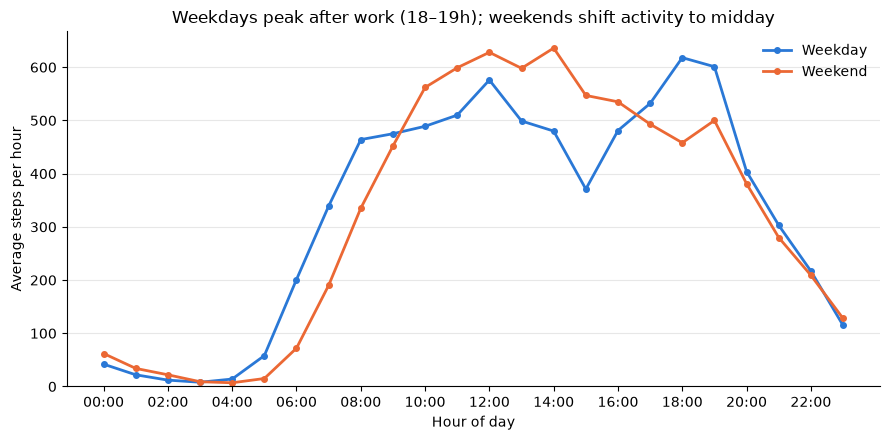

In [21]:
labels = hours_dim["hour_label"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(profile.index, profile["Weekday"], marker="o", markersize=4, linewidth=2,
        color="#2A78D6", label="Weekday")
ax.plot(profile.index, profile["Weekend"], marker="o", markersize=4, linewidth=2,
        color="#EB6834", label="Weekend")

ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels(labels.loc[list(range(0, 24, 2))])
ax.set_ylim(bottom=0)
ax.set_xlabel("Hour of day")
ax.set_ylabel("Average steps per hour")
ax.set_title("Weekdays peak after work (18–19h); weekends shift activity to midday")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)

fig.tight_layout()
fig.savefig("../docs/figures/h3_hourly_profile.png", dpi=150)
plt.show()

In [19]:
weekend_steps = (
    valid.groupby(["user_id", "is_weekend"])["total_steps"].mean()
    .unstack()
    .dropna()
)
w_we = stats.wilcoxon(weekend_steps[False], weekend_steps[True])
print(f"Users with valid weekdays and weekend days: {len(weekend_steps)}")
print(f"Mean daily steps: weekday = {weekend_steps[False].mean():.0f}, "
      f"weekend = {weekend_steps[True].mean():.0f}")
print(f"Median daily steps: weekday = {weekend_steps[False].median():.0f}, "
      f"weekend = {weekend_steps[True].median():.0f}")
print(f"Higher on weekends: {(weekend_steps[True] > weekend_steps[False]).sum()} users")
print(f"Wilcoxon signed-rank: W = {w_we.statistic:.1f}, p = {w_we.pvalue:.3f}")

by_dow = (
    valid.groupby(["user_id", "day_of_week"])["total_steps"].mean()
    .groupby("day_of_week").mean()
    .round()
)
by_dow

Users with valid weekdays and weekend days: 34
Mean daily steps: weekday = 7937, weekend = 7839
Median daily steps: weekday = 7203, weekend = 6674
Higher on weekends: 18 users
Wilcoxon signed-rank: W = 297.0, p = 1.000


day_of_week
1    7896.0
2    8274.0
3    7835.0
4    8141.0
5    7779.0
6    8088.0
7    7610.0
Name: total_steps, dtype: Float64

**Finding (H3):** Users walk the same amount on weekdays and weekends
(mean 7,937 vs 7,839 steps; p = 1.00), but at different times. On weekdays activity
peaks after work (18:00–19:00) with a second peak at lunchtime; on weekends the
morning starts later and activity concentrates around midday, with the afternoon
share of daily steps rising from 38% to 44%.

## 4. H4: Is sedentary time related to sleep?

In [22]:
import statsmodels.formula.api as smf

sleep = data["fact_sleep"][["user_id", "sleep_date", "total_minutes_asleep"]].copy()
sleep["sleep_date"] = pd.to_datetime(sleep["sleep_date"].astype(str))

days = valid[["user_id", "activity_date", "sedentary_minutes",
              "active_minutes", "is_weekend"]].copy()
days["activity_date"] = pd.to_datetime(days["activity_date"].astype(str))
days["is_weekend"] = days["is_weekend"].astype(bool)
days["sedentary_share"] = (
    100 * days["sedentary_minutes"] / (days["sedentary_minutes"] + days["active_minutes"])
)

same_day = days.merge(
    sleep, left_on=["user_id", "activity_date"], right_on=["user_id", "sleep_date"]
)
next_night = (
    days.assign(next_date=days["activity_date"] + pd.Timedelta(days=1))
    .merge(sleep, left_on=["user_id", "next_date"], right_on=["user_id", "sleep_date"])
)

print(f"Same-day pairs:   {len(same_day)} days, {same_day['user_id'].nunique()} users")
print(f"Next-night pairs: {len(next_night)} days, {next_night['user_id'].nunique()} users")

Same-day pairs:   816 days, 25 users
Next-night pairs: 811 days, 25 users


In [23]:
r_same = stats.pearsonr(same_day["sedentary_minutes"], same_day["total_minutes_asleep"])
print(f"Same day, sedentary minutes vs minutes asleep: r = {r_same.statistic:.2f}, "
      f"p = {r_same.pvalue:.1e}")

same_day["user"] = same_day["user_id"].astype(str)
mech = smf.ols("total_minutes_asleep ~ sedentary_minutes + C(user)", data=same_day).fit(
    cov_type="cluster", cov_kwds={"groups": same_day["user_id"]}
)
print(f"Within the same person: +1 h sedentary -> "
      f"{60 * mech.params['sedentary_minutes']:.1f} min of sleep")

Same day, sedentary minutes vs minutes asleep: r = -0.69, p = 1.7e-118
Within the same person: +1 h sedentary -> -32.4 min of sleep


In [24]:
user_means = next_night.groupby("user_id")[["sedentary_share", "total_minutes_asleep"]].mean()

r_between = stats.pearsonr(user_means["sedentary_share"], user_means["total_minutes_asleep"])
rho_between = stats.spearmanr(user_means["sedentary_share"], user_means["total_minutes_asleep"])
print(f"Between users ({len(user_means)}): Pearson r = {r_between.statistic:.2f} "
      f"(p = {r_between.pvalue:.3f}), Spearman rho = {rho_between.statistic:.2f} "
      f"(p = {rho_between.pvalue:.3f})")

Between users (25): Pearson r = -0.39 (p = 0.052), Spearman rho = -0.50 (p = 0.010)


In [25]:
next_night["user"] = next_night["user_id"].astype(str)
cluster = {"groups": next_night["user_id"]}

pooled = smf.ols(
    "total_minutes_asleep ~ sedentary_share + is_weekend", data=next_night
).fit(cov_type="cluster", cov_kwds=cluster)

fixed_effects = smf.ols(
    "total_minutes_asleep ~ sedentary_share + is_weekend + C(user)", data=next_night
).fit(cov_type="cluster", cov_kwds=cluster)

for name, model in [("Pooled OLS", pooled), ("User fixed effects", fixed_effects)]:
    ci = model.conf_int().loc["sedentary_share"]
    print(f"{name}: +1 pp sedentary share -> {model.params['sedentary_share']:+.2f} min sleep "
          f"(95% CI {ci[0]:.2f} to {ci[1]:.2f}, p = {model.pvalues['sedentary_share']:.3f}); "
          f"day before a weekend night: {model.params['is_weekend[T.True]']:+.1f} min "
          f"(p = {model.pvalues['is_weekend[T.True]']:.3f}); n = {int(model.nobs)}")

Pooled OLS: +1 pp sedentary share -> -1.08 min sleep (95% CI -2.09 to -0.06, p = 0.037); day before a weekend night: +19.3 min (p = 0.022); n = 811
User fixed effects: +1 pp sedentary share -> +0.16 min sleep (95% CI -0.55 to 0.86, p = 0.662); day before a weekend night: +23.3 min (p = 0.004); n = 811


In [27]:
short_nights = next_night["total_minutes_asleep"] < 180
print(f"Nights under 3 h asleep: {short_nights.sum()} "
      f"({next_night.loc[short_nights, 'user_id'].nunique()} users)")

robust = next_night[~short_nights]
robust_means = robust.groupby("user_id")[["sedentary_share", "total_minutes_asleep"]].mean()
rho_robust = stats.spearmanr(robust_means["sedentary_share"], robust_means["total_minutes_asleep"])
r_robust = stats.pearsonr(robust_means["sedentary_share"], robust_means["total_minutes_asleep"])
print(f"Between users, nights >= 3 h ({len(robust_means)} users): "
      f"Spearman rho = {rho_robust.statistic:.2f} (p = {rho_robust.pvalue:.3f}), "
      f"Pearson r = {r_robust.statistic:.2f} (p = {r_robust.pvalue:.3f})")

fe_robust = smf.ols(
    "total_minutes_asleep ~ sedentary_share + is_weekend + C(user)", data=robust
).fit(cov_type="cluster", cov_kwds={"groups": robust["user_id"]})
ci = fe_robust.conf_int().loc["sedentary_share"]
print(f"Fixed effects, nights >= 3 h: {fe_robust.params['sedentary_share']:+.2f} min per pp "
      f"(95% CI {ci[0]:.2f} to {ci[1]:.2f}, p = {fe_robust.pvalues['sedentary_share']:.3f}); "
      f"weekend {fe_robust.params['is_weekend[T.True]']:+.1f} min "
      f"(p = {fe_robust.pvalues['is_weekend[T.True]']:.3f})")

Nights under 3 h asleep: 41 (18 users)
Between users, nights >= 3 h (22 users): Spearman rho = -0.34 (p = 0.118), Pearson r = -0.17 (p = 0.450)
Fixed effects, nights >= 3 h: +0.47 min per pp (95% CI -0.09 to 1.04, p = 0.101); weekend +22.5 min (p = 0.008)


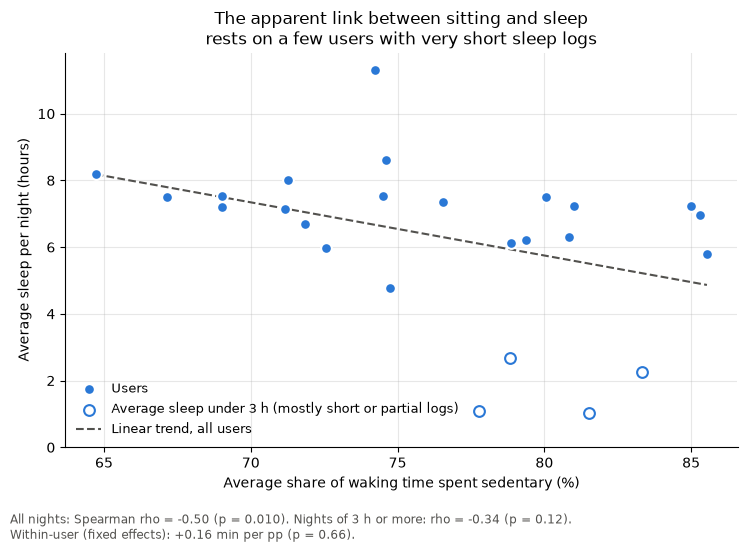

In [29]:
short_users = user_means["total_minutes_asleep"] < 180

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.scatter(user_means.loc[~short_users, "sedentary_share"],
           user_means.loc[~short_users, "total_minutes_asleep"] / 60,
           s=60, color="#2A78D6", edgecolor="white", linewidth=1.5, zorder=3,
           label="Users")
ax.scatter(user_means.loc[short_users, "sedentary_share"],
           user_means.loc[short_users, "total_minutes_asleep"] / 60,
           s=60, facecolor="white", edgecolor="#2A78D6", linewidth=1.5, zorder=3,
           label="Average sleep under 3 h (mostly short or partial logs)")

slope, intercept = np.polyfit(user_means["sedentary_share"],
                              user_means["total_minutes_asleep"] / 60, 1)
x_line = np.linspace(user_means["sedentary_share"].min(), user_means["sedentary_share"].max(), 50)
ax.plot(x_line, intercept + slope * x_line, color="#52514E", linewidth=1.5, linestyle="--",
        label="Linear trend, all users")

ax.set_ylim(0, None)
ax.set_xlabel("Average share of waking time spent sedentary (%)")
ax.set_ylabel("Average sleep per night (hours)")
ax.set_title("The apparent link between sitting and sleep\n"
             "rests on a few users with very short sleep logs")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower left", fontsize=9)
fig.text(0.01, 0.01,
         f"All nights: Spearman rho = {rho_between.statistic:.2f} (p = {rho_between.pvalue:.3f}). "
         f"Nights of 3 h or more: rho = {rho_robust.statistic:.2f} (p = {rho_robust.pvalue:.2f}).\n"
         f"Within-user (fixed effects): {fixed_effects.params['sedentary_share']:+.2f} min per pp "
         f"(p = {fixed_effects.pvalues['sedentary_share']:.2f}).",
         fontsize=8.5, color="#52514E")

fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig("../docs/figures/h4_sedentary_sleep.png", dpi=150)
plt.show()

**Finding (H4):** The strong same-day correlation between sedentary minutes and sleep
(r = -0.69) is largely mechanical: a day has 1,440 minutes, so a longer night leaves
fewer minutes to be sedentary. Measured properly (sedentary share of waking time vs
sleep the following night), there is no robust relationship. Within the same person,
a more sedentary day is not followed by a shorter night (fixed effects: +0.16 min per
percentage point, 95% CI -0.55 to 0.86). An apparent between-user association
(Spearman rho = -0.50) disappears once nights under 3 hours, mostly naps or partial
logs, are excluded (rho = -0.34, p = 0.12). The only robust effect: sleep is about
20 minutes longer after weekend days.